In [ ]:

import pandas as pd
import numpy as np

from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

# ============================================================
# 1. CONFIGURAÇÕES

RANDOM_STATE = 42
TEST_SIZE = 0.20
INITIAL_LABELED_SIZE = 200

TARGET_COL = "received_callback"
SENSITIVE_COLS = ["race", "gender"]

# ============================================================
# 2. CARREGAMENTO

df = pd.read_csv("resume.csv")
df.columns = df.columns.str.strip()

print("Dimensão original:", df.shape)
print("\nColunas disponíveis:")
print(df.columns.tolist())

required = [
    TARGET_COL, "race", "gender", "job_ad_id"
]

missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Colunas obrigatórias em falta: {missing}")

# ============================================================
# 3. LIMPEZA DO TARGET

def encode_binary(series):
    """
    Converte valores binários comuns para 0 e 1.
    Valores desconhecidos ficam como NaN.
    """
    mapping = {
        "0": 0,
        "1": 1,
        "false": 0,
        "true": 1,
        "no": 0,
        "yes": 1,
        "n": 0,
        "y": 1
    }

    clean = series.astype("string").str.strip().str.lower()
    return clean.map(mapping).astype(float)


df[TARGET_COL] = encode_binary(df[TARGET_COL])

# Remover apenas observações sem target
df = df.dropna(subset=[TARGET_COL]).copy()
df[TARGET_COL] = df[TARGET_COL].astype(int)

# ============================================================
# 4. ATRIBUTOS SENSÍVEIS

df["race"] = (
    df["race"].astype("string").str.strip().str.lower()
)

df["gender"] = (
    df["gender"].astype("string").str.strip().str.lower()
)

race_map = {
    "black": 0,
    "white": 1
}

gender_map = {
    "f": 0,
    "m": 1,
    "female": 0,
    "male": 1
}

df["sens_race"] = df["race"].map(race_map)
df["sens_gender"] = df["gender"].map(gender_map)

if df[["sens_race", "sens_gender"]].isna().any().any():
    raise ValueError(
        "Existem valores desconhecidos em race ou gender."
    )

df["sens_race"] = df["sens_race"].astype(int)
df["sens_gender"] = df["sens_gender"].astype(int)

# Quatro grupos:
# 0 = Black Female
# 1 = Black Male
# 2 = White Female
# 3 = White Male

df["sens_intersectional"] = (
    2 * df["sens_race"] + df["sens_gender"]
)

# ============================================================
# 5. SELEÇÃO DAS FEATURES

# Variáveis numéricas e indicadores binários
NUMERIC_COLS = [
    "years_college",
    "college_degree",
    "honors",
    "worked_during_school",
    "years_experience",
    "computer_skills",
    "special_skills",
    "volunteer",
    "military",
    "employment_holes",
    "has_email_address",
    "job_fed_contractor",
    "job_equal_opp_employer",
    "job_req_any",
    "job_req_communication",
    "job_req_education",
    "job_req_min_experience",
    "job_req_computer",
    "job_req_organization"
]

# Variáveis categóricas nominais
NOMINAL_COLS = [
    "job_city",
    "job_industry",
    "job_type",
    "job_ownership",
    "job_req_school",
    "resume_quality"
]

# Manter apenas variáveis existentes
NUMERIC_COLS = [
    c for c in NUMERIC_COLS if c in df.columns
]

NOMINAL_COLS = [
    c for c in NOMINAL_COLS if c in df.columns
]

# Converter indicadores textuais e variáveis numéricas
for col in NUMERIC_COLS:
    if (
        pd.api.types.is_bool_dtype(df[col])
        or pd.api.types.is_object_dtype(df[col])
        or pd.api.types.is_string_dtype(df[col])
    ):
        cleaned = df[col].astype("string").str.strip().str.lower()
        cleaned = cleaned.replace({
            "true": "1",
            "false": "0",
            "yes": "1",
            "no": "0",
            "some": "0.5"  # <-- Recupera 1064 registos em job_req_min_experience
        })
        df[col] = pd.to_numeric(cleaned, errors="coerce")
    else:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Preparar dados brutos
FEATURE_COLS = NUMERIC_COLS + NOMINAL_COLS

if not FEATURE_COLS:
    raise ValueError("Não foram encontradas features válidas.")

X_raw = df[FEATURE_COLS].copy()
y = df[TARGET_COL].to_numpy()

sens_race = df["sens_race"].to_numpy()
sens_gender = df["sens_gender"].to_numpy()
sens_intersectional = df["sens_intersectional"].to_numpy()

Dimensão original: (4870, 30)

Colunas disponíveis:
['job_ad_id', 'job_city', 'job_industry', 'job_type', 'job_fed_contractor', 'job_equal_opp_employer', 'job_ownership', 'job_req_any', 'job_req_communication', 'job_req_education', 'job_req_min_experience', 'job_req_computer', 'job_req_organization', 'job_req_school', 'received_callback', 'firstname', 'race', 'gender', 'years_college', 'college_degree', 'honors', 'worked_during_school', 'years_experience', 'computer_skills', 'special_skills', 'volunteer', 'military', 'employment_holes', 'has_email_address', 'resume_quality']


### Train-Test-Split

In [ ]:
# ============================================================
# 6. TRAIN / TEST SPLIT

# Dividir por anúncio de emprego.
# Assim, candidaturas ao mesmo anúncio não aparecem
# simultaneamente no treino e no teste.

groups = df["job_ad_id"].fillna(
    "__missing_job_ad__"
).astype(str)

splitter = GroupShuffleSplit(
    n_splits=20,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

train_idx = None
test_idx = None

# Procurar uma divisão com ambas as classes em treino e teste
for tr, te in splitter.split(X_raw, y, groups=groups):
    if len(np.unique(y[tr])) == 2 and len(np.unique(y[te])) == 2:
        train_idx, test_idx = tr, te
        break

if train_idx is None:
    raise ValueError(
        "Não foi possível criar treino e teste com ambas as classes."
    )

X_train_raw = X_raw.iloc[train_idx].copy()
X_test_raw = X_raw.iloc[test_idx].copy()

y_train = y[train_idx]
y_test = y[test_idx]

sens_race_train = sens_race[train_idx]
sens_race_test = sens_race[test_idx]

sens_gender_train = sens_gender[train_idx]
sens_gender_test = sens_gender[test_idx]

sens_intersectional_train = sens_intersectional[train_idx]
sens_intersectional_test = sens_intersectional[test_idx]

### Criação da Pool

In [ ]:
# ============================================================
# 7. INITIAL LABELED SET / UNLABELED POOL

# Os índices seguintes são relativos ao conjunto de treino
train_positions = np.arange(len(y_train))

if INITIAL_LABELED_SIZE >= len(y_train):
    raise ValueError(
        "INITIAL_LABELED_SIZE tem de ser inferior "
        "ao número de observações de treino."
    )

initial_idx, pool_idx = train_test_split(
    train_positions,
    train_size=INITIAL_LABELED_SIZE,
    stratify=y_train,
    random_state=RANDOM_STATE
)

X_initial_raw = X_train_raw.iloc[initial_idx]
X_pool_raw = X_train_raw.iloc[pool_idx]

y_initial = y_train[initial_idx]
y_pool = y_train[pool_idx]

# NOTA:
# y_pool existe apenas para simular o anotador humano.
# O modelo não deve aceder a estes labels antes de os consultar.

sens_race_initial = sens_race_train[initial_idx]
sens_race_pool = sens_race_train[pool_idx]

sens_gender_initial = sens_gender_train[initial_idx]
sens_gender_pool = sens_gender_train[pool_idx]

sens_intersectional_initial = sens_intersectional_train[initial_idx]
sens_intersectional_pool = sens_intersectional_train[pool_idx]

# ============================================================
# 8. PIPELINE DE PRÉ-PROCESSAMENTO

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        keep_empty_features=True
    ))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, NUMERIC_COLS),
    ("categorical", categorical_pipeline, NOMINAL_COLS)
])

# Ajustar APENAS no conjunto inicialmente rotulado.
# Evita aprender estatísticas do teste e da pool.

X_initial = preprocessor.fit_transform(X_initial_raw)

X_pool = preprocessor.transform(X_pool_raw)
X_test = preprocessor.transform(X_test_raw)

X_initial = np.asarray(X_initial, dtype=float)
X_pool = np.asarray(X_pool, dtype=float)
X_test = np.asarray(X_test, dtype=float)

# Conjuntos completos transformados, para referência.
# No Active Learning, treinar inicialmente apenas com X_initial.
X_train = preprocessor.transform(X_train_raw)
X_train = np.asarray(X_train, dtype=float)

X = np.empty((len(df), X_initial.shape[1]), dtype=float)
X[train_idx] = X_train
X[test_idx] = X_test

feature_names = preprocessor.get_feature_names_out()

### Validação e Resumo do Pré-Processamento

In [ ]:


# ============================================================
# 9. VALIDAÇÕES FINAIS

assert X_initial.shape[0] == len(y_initial)
assert X_pool.shape[0] == len(y_pool)
assert X_test.shape[0] == len(y_test)

assert np.isfinite(X_initial).all()
assert np.isfinite(X_pool).all()
assert np.isfinite(X_test).all()

assert len(set(train_idx) & set(test_idx)) == 0

assert set(groups.iloc[train_idx]).isdisjoint(
    set(groups.iloc[test_idx])
)

# ============================================================
# 10. RESUMO

print("\n" + "=" * 55)
print("RESUMO DO PRÉ-PROCESSAMENTO")
print("=" * 55)

print(f"Total de observações: {len(df)}")
print(f"Features finais: {X_initial.shape[1]}")

print("\nDivisão dos dados:")
print(f"  Initial labeled: {len(y_initial)}")
print(f"  Unlabeled pool:  {len(y_pool)}")
print(f"  Test:            {len(y_test)}")

print("\nTaxa de callbacks:")
print(f"  Dataset: {np.mean(y)*100:.2f}%")
print(f"  Inicial: {np.mean(y_initial)*100:.2f}%")
print(f"  Pool:    {np.mean(y_pool)*100:.2f}%")
print(f"  Teste:   {np.mean(y_test)*100:.2f}%")

print("\nDistribuição racial:")
print(df["race"].value_counts())

print("\nDistribuição por género:")
print(df["gender"].value_counts())

print("\nGrupos interseccionais:")
group_names = {
    0: "Black Female",
    1: "Black Male",
    2: "White Female",
    3: "White Male"
}

counts = df["sens_intersectional"].value_counts()

for code, name in group_names.items():
    print(f"  {name}: {counts.get(code, 0)}")

print("\nCallbacks por raça:")
print(
    df.groupby("race")[TARGET_COL]
    .agg(["count", "mean"])
    .rename(columns={"mean": "callback_rate"})
)

print("\nValores em falta após transformação:")
print("  Inicial:", np.isnan(X_initial).sum())
print("  Pool:", np.isnan(X_pool).sum())
print("  Teste:", np.isnan(X_test).sum())

print("\nPré-processamento concluído!")


RESUMO DO PRÉ-PROCESSAMENTO
Total de observações: 4870
Features finais: 43

Divisão dos dados:
  Initial labeled: 200
  Unlabeled pool:  3704
  Test:            966

Taxa de callbacks:
  Dataset: 8.05%
  Inicial: 8.50%
  Pool:    8.32%
  Teste:   6.94%

Distribuição racial:
race
white    2435
black    2435
Name: count, dtype: Int64

Distribuição por género:
gender
f    3746
m    1124
Name: count, dtype: Int64

Grupos interseccionais:
  Black Female: 1886
  Black Male: 549
  White Female: 1860
  White Male: 575

Callbacks por raça:
       count  callback_rate
race                       
black   2435       0.064476
white   2435       0.096509

Valores em falta após transformação:
  Inicial: 0
  Pool: 0
  Teste: 0

Pré-processamento concluído!


### Exploratory Data Analysis

In [86]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 110

# Para a análise exploratória, utilizar o dataset original
# já com target e atributos sensíveis tratados.
df_eda = df.copy()

print("Dimensão do dataset:", df_eda.shape)
print("Features numéricas:", len(NUMERIC_COLS))
print("Features categóricas:", len(NOMINAL_COLS))


Dimensão do dataset: (4870, 33)
Features numéricas: 19
Features categóricas: 6


#### Class Balance

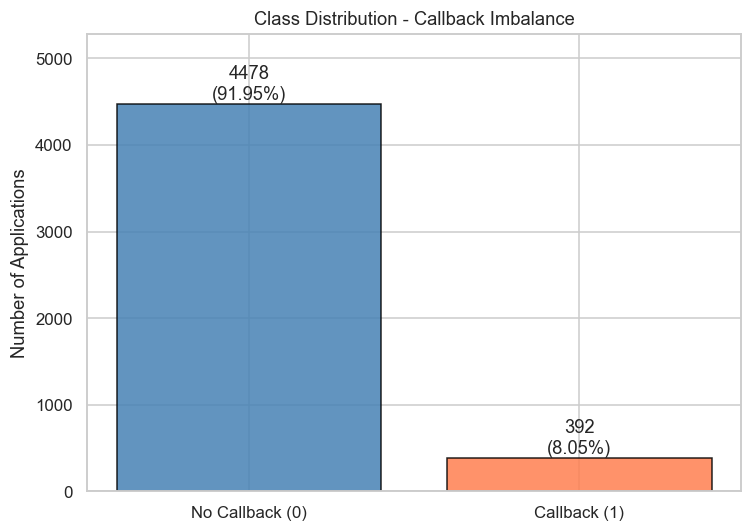

In [87]:
target_counts = (
    df_eda["received_callback"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["No Callback (0)", "Callback (1)"],
    target_counts.values,
    color=["steelblue", "coral"],
    edgecolor="black",
    alpha=0.85
)

for bar, count in zip(bars, target_counts.values):
    percentage = 100 * count / len(df_eda)
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count}\n({percentage:.2f}%)",
        ha="center",
        va="bottom"
    )

ax.set_title("Class Distribution - Callback Imbalance")
ax.set_ylabel("Number of Applications")
ax.set_ylim(0, target_counts.max() * 1.18)

plt.tight_layout()
plt.show()


#### Callback By Race and Gender

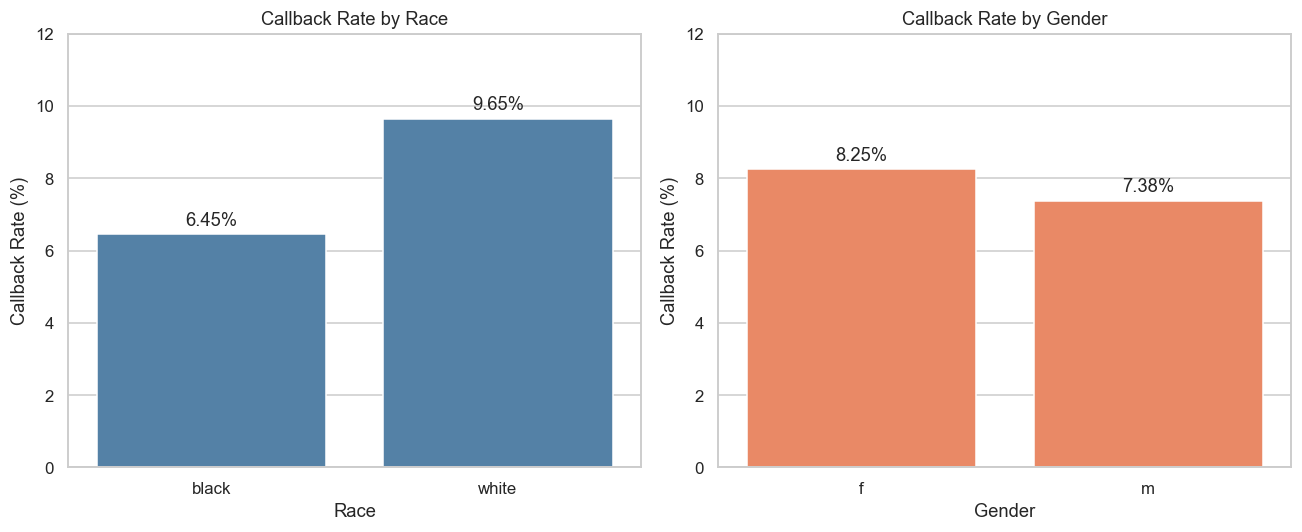

In [88]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Taxa por raça
race_rates = (
    df_eda.groupby("race")["received_callback"]
    .mean()
    .mul(100)
    .sort_index()
)

sns.barplot(
    x=race_rates.index,
    y=race_rates.values,
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Callback Rate by Race")
axes[0].set_xlabel("Race")
axes[0].set_ylabel("Callback Rate (%)")

# Taxa por género
gender_rates = (
    df_eda.groupby("gender")["received_callback"]
    .mean()
    .mul(100)
    .sort_index()
)

sns.barplot(
    x=gender_rates.index,
    y=gender_rates.values,
    ax=axes[1],
    color="coral"
)

axes[1].set_title("Callback Rate by Gender")
axes[1].set_xlabel("Gender")
axes[1].set_ylabel("Callback Rate (%)")

for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f%%", padding=3)
    ax.set_ylim(0, max(ax.get_ylim()[1], 12))

plt.tight_layout()
plt.show()


#### Callback Rate by Intersectional Group

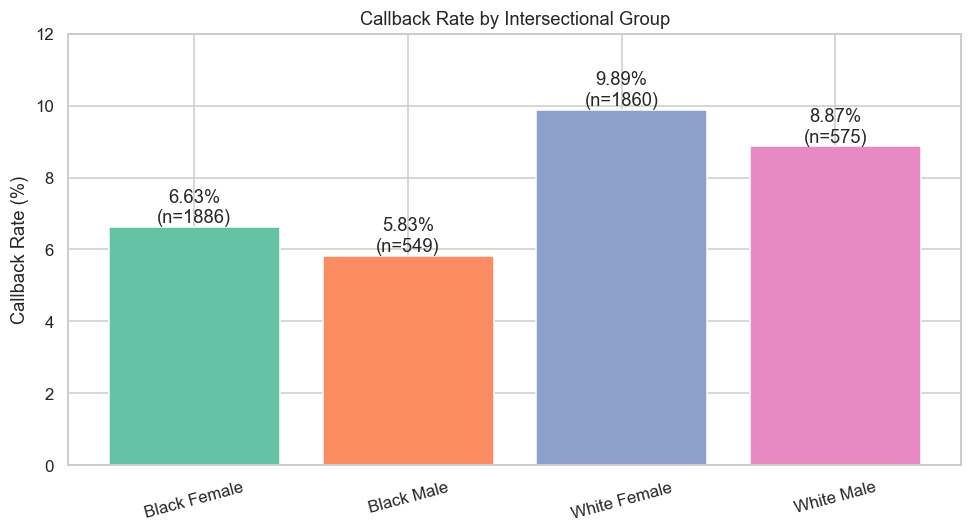

In [89]:

group_names = {
    0: "Black Female",
    1: "Black Male",
    2: "White Female",
    3: "White Male"
}

intersectional_rates = (
    df_eda.groupby("sens_intersectional")["received_callback"]
    .agg(["mean", "count"])
    .reindex([0, 1, 2, 3])
)

intersectional_rates.index = [
    group_names[i] for i in intersectional_rates.index
]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    intersectional_rates.index,
    intersectional_rates["mean"] * 100,
    color=sns.color_palette("Set2", 4)
)

for bar, (_, row) in zip(
    bars, intersectional_rates.iterrows()
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{row['mean']*100:.2f}%\n(n={int(row['count'])})",
        ha="center",
        va="bottom"
    )

ax.set_title("Callback Rate by Intersectional Group")
ax.set_ylabel("Callback Rate (%)")
ax.set_ylim(
    0,
    max(12, intersectional_rates["mean"].max() * 120)
)
ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


#### Missing Values

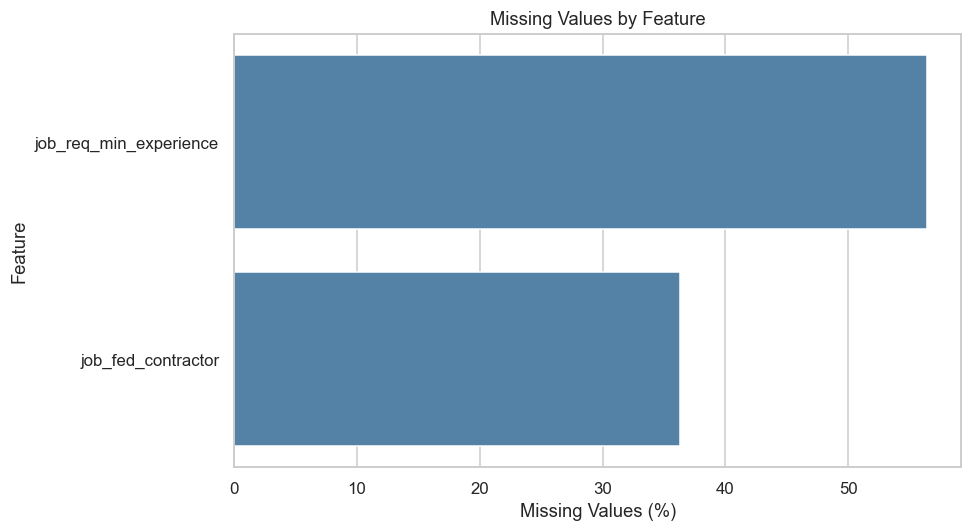

In [ ]:



missing_pct = (
    df_eda.isna().mean() * 100
).sort_values(ascending=False)

missing_pct = missing_pct[missing_pct > 0]

if missing_pct.empty:
    print("Não existem valores em falta no dataframe.")
else:
    fig, ax = plt.subplots(figsize=(9, 5))

    sns.barplot(
        x=missing_pct.values,
        y=missing_pct.index,
        color="steelblue",
        ax=ax
    )

    ax.set_title("Missing Values by Feature")
    ax.set_xlabel("Missing Values (%)")
    ax.set_ylabel("Feature")

    plt.tight_layout()
    plt.show()


#### Boxplot de Outliers

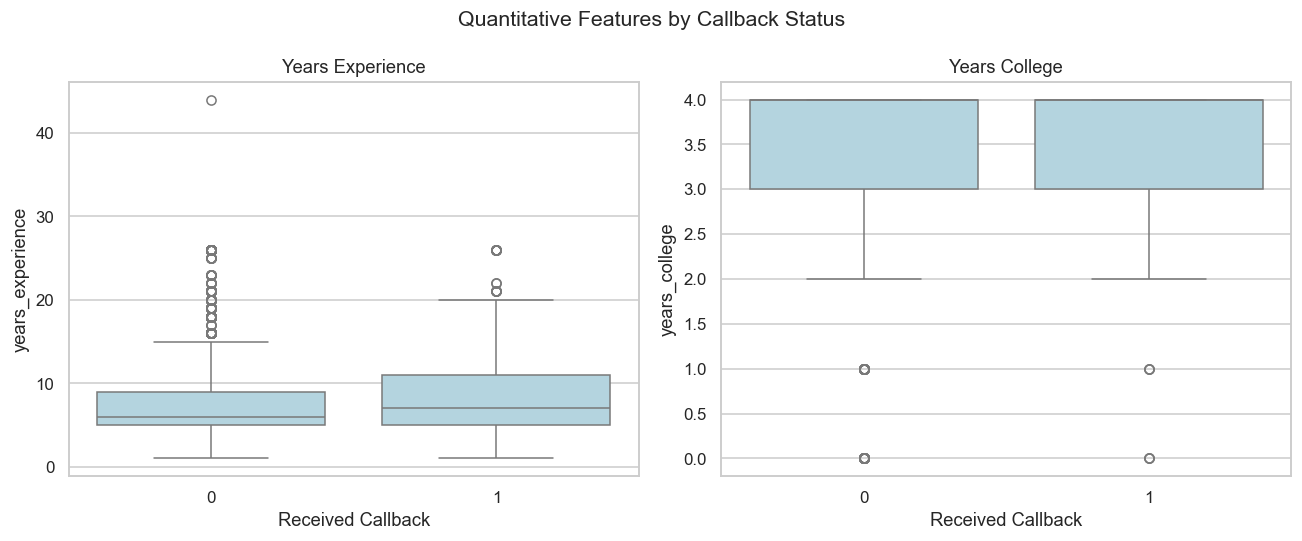

In [91]:

quantitative_features = [
    "years_experience",
    "years_college"
]

fig, axes = plt.subplots(
    1, len(quantitative_features),
    figsize=(12, 5)
)

for ax, col in zip(axes, quantitative_features):
    sns.boxplot(
        data=df_eda,
        x="received_callback",
        y=col,
        color="lightblue",
        ax=ax
    )

    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("Received Callback")
    ax.set_ylabel(col)

plt.suptitle(
    "Quantitative Features by Callback Status",
    fontsize=14
)
plt.tight_layout()
plt.show()


### Active Learning

In [ ]:
# ============================================================
# ACTIVE LEARNING - QUERY STRATEGIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KernelDensity
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

def select_samples(
    model,
    X_pool,
    strategy,
    batch_size,
    rng,
    committee=None,
    bandwidth=1.0
):
    """
    Seleciona exemplos da pool de acordo com a estratégia.
    Devolve índices relativos à pool atual.
    """
    k = min(batch_size, len(X_pool))

    if strategy == "random":
        return rng.choice(len(X_pool), size=k, replace=False)

    probabilities = model.predict_proba(X_pool)

    # Nota teórica: em classificação binária (K=2), least_confidence,
    # entropy e margin são transformações monotónicas de |p - 0.5|.
    if strategy == "least_confidence":
        scores = 1 - probabilities.max(axis=1)

    elif strategy == "entropy":
        p = np.clip(probabilities, 1e-12, 1.0)
        scores = -np.sum(p * np.log(p), axis=1)

    elif strategy == "margin":
        sorted_p = np.sort(probabilities, axis=1)
        margin = sorted_p[:, -1] - sorted_p[:, -2]
        scores = -margin

    elif strategy == "qbc":
        # Query-by-Committee (Vote Entropy):
        # Usa um comité explícito ou as árvores individuais da RandomForest
        members = (
            committee
            if committee is not None
            else getattr(model, "estimators_", None)
        )
        if members is None:
            raise ValueError(
                "A estratégia 'qbc' requer um comité ou um modelo com 'estimators_'."
            )

        m = len(members)
        votes = np.vstack([clf.predict(X_pool) for clf in members]).T
        class_list = np.unique(votes)

        vote_counts = np.zeros((X_pool.shape[0], len(class_list)))
        for i, c in enumerate(class_list):
            vote_counts[:, i] = np.sum(votes == c, axis=1)

        p_vote = np.clip(vote_counts / m, 1e-12, 1.0)
        scores = -np.sum(p_vote * np.log(p_vote), axis=1)

    elif strategy == "density_weighted":
        # Density-Weighted Uncertainty (Settles, 2010):
        # Combina entropia preditiva com a densidade local na pool (KDE)
        p = np.clip(probabilities, 1e-12, 1.0)
        uncertainty = -np.sum(p * np.log(p), axis=1)

        kde = KernelDensity(bandwidth=bandwidth)
        kde.fit(X_pool)
        log_dens = kde.score_samples(X_pool)

        # Subtrair o máximo evita underflow numérico em alta dimensão (43 features)
        density = np.exp(log_dens - np.max(log_dens))
        scores = uncertainty * density

    else:
        raise ValueError(f"Unknown strategy: {strategy}")

    # Selecionar os k exemplos com maior score
    return np.argsort(scores)[-k:][::-1]

#### Fairness Metrics

In [ ]:

# ============================================================
# FAIRNESS METRICS

def calculate_fairness(y_true, y_pred, sensitive):
    """
    Calcula TPR e FPR por grupo racial.

    Equalized Odds Difference =
        max(|TPR_black - TPR_white|,
            |FPR_black - FPR_white|)
    """

    results = {}

    for group in [0, 1]:
        mask = sensitive == group

        tn, fp, fn, tp = confusion_matrix(
            y_true[mask],
            y_pred[mask],
            labels=[0, 1]
        ).ravel()

        tpr = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        fpr = fp / (fp + tn) if (fp + tn) > 0 else np.nan

        results[group] = {"TPR": tpr, "FPR": fpr}

    tpr_values = [results[g]["TPR"] for g in [0, 1]]
    fpr_values = [results[g]["FPR"] for g in [0, 1]]

    if not np.all(np.isfinite(tpr_values + fpr_values)):
        eod = np.nan
    else:
        tpr_gap = abs(tpr_values[0] - tpr_values[1])
        fpr_gap = abs(fpr_values[0] - fpr_values[1])
        eod = max(tpr_gap, fpr_gap)

    return eod


#### Active Learning Experiment

In [ ]:

# ============================================================
# ACTIVE LEARNING EXPERIMENT


def run_active_learning(
    strategy,
    n_iterations=20,
    batch_size=10,
    seed=42
):
    rng = np.random.default_rng(seed)

    # Cópias independentes para cada experiência
    X_labeled = X_initial.copy()
    y_labeled = y_initial.copy()

    X_unlabeled = X_pool.copy()
    y_oracle = y_pool.copy()

    history = []

    for iteration in range(n_iterations + 1):

        # 1. Treinar modelo (regularizado para evitar folhas puras e calibrar probabilidades)
        model = RandomForestClassifier(
            n_estimators=200,
            max_depth=6,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=seed,
            n_jobs=-1
        )

        model.fit(X_labeled, y_labeled)

        # 2. Avaliar no conjunto de teste
        y_pred = model.predict(X_test)
        y_proba = model.predict_proba(X_test)[:, 1]

        # 3. Métricas de desempenho
        bal_acc = balanced_accuracy_score(
            y_test, y_pred
        )

        f1 = f1_score(
            y_test, y_pred,
            zero_division=0
        )

        ap = average_precision_score(
            y_test, y_proba
        )

        # 4. Fairness
        eod = calculate_fairness(
            y_test,
            y_pred,
            sens_race_test
        )

        history.append({
            "strategy": strategy,
            "iteration": iteration,
            "n_labeled": len(y_labeled),
            "balanced_accuracy": bal_acc,
            "f1": f1,
            "average_precision": ap,
            "equalized_odds": eod,
            "positive_predictions": int(y_pred.sum())
        })

        # Última iteração: apenas avaliação
        if iteration == n_iterations:
            break

        if len(X_unlabeled) == 0:
            break

        # 5. Seleção de exemplos
        query_idx = select_samples(
            model,
            X_unlabeled,
            strategy,
            batch_size,
            rng
        )

        # 6. Consulta ao oracle simulado
        X_new = X_unlabeled[query_idx]
        y_new = y_oracle[query_idx]

        # 7. Ensinar o modelo
        X_labeled = np.vstack([
            X_labeled, X_new
        ])

        y_labeled = np.concatenate([
            y_labeled, y_new
        ])

        # 8. Remover exemplos da pool
        X_unlabeled = np.delete(
            X_unlabeled,
            query_idx,
            axis=0
        )

        y_oracle = np.delete(
            y_oracle,
            query_idx
        )

    return pd.DataFrame(history)


#### Run Experiments

In [ ]:

# ============================================================
# RUN BASELINE EXPERIMENTS

strategies = [
    "random",
    "least_confidence",
    "qbc",
    "density_weighted"
]

results = []

for strategy in strategies:
    print(f"Running: {strategy}")

    history = run_active_learning(
        strategy=strategy,
        n_iterations=20,
        batch_size=10,
        seed=42
    )

    results.append(history)

results_df = pd.concat(
    results,
    ignore_index=True
)

display(
    results_df.groupby("strategy").tail(1).round(4)
)


Running: random
Running: least_confidence
Running: qbc
Running: density_weighted


,strategy,iteration,n_labeled,balanced_accuracy,f1,average_precision,equalized_odds,positive_predictions
20,random,20,400,0.5145,0.0885,0.1192,0.1013,46
41,least_confidence,20,400,0.5094,0.0506,0.1245,0.0645,12
62,qbc,20,400,0.5231,0.1071,0.1289,0.0134,45
83,density_weighted,20,400,0.5156,0.0901,0.1017,0.0188,44


#### Learning Curves

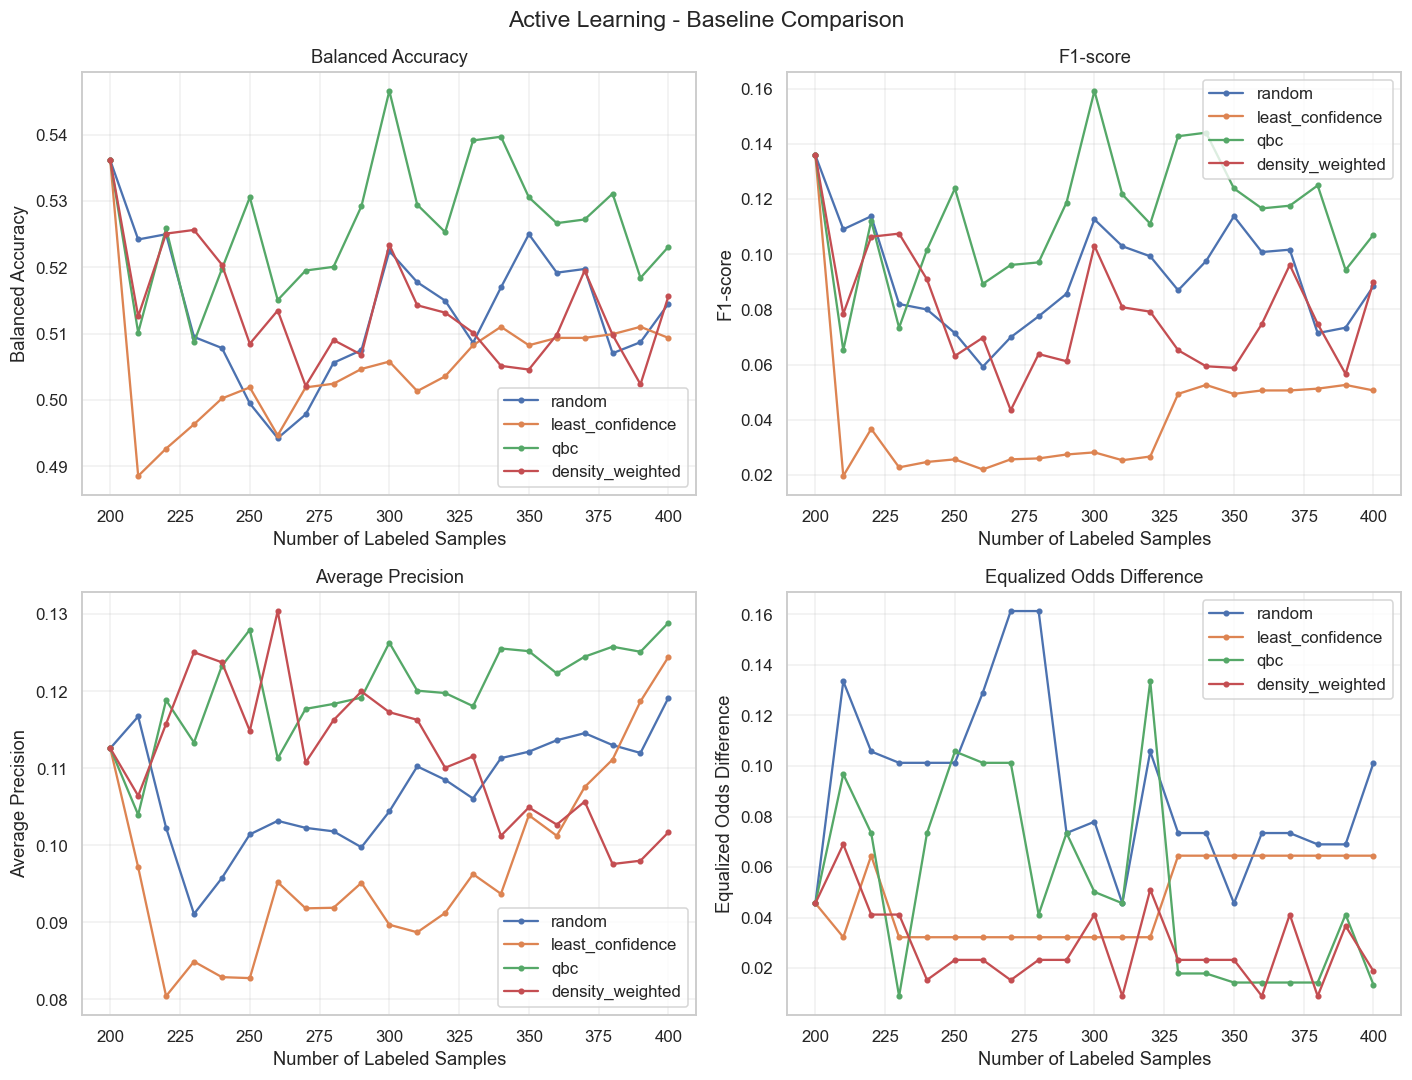

In [ ]:

# ============================================================
# LEARNING CURVES


metrics = [
    ("balanced_accuracy", "Balanced Accuracy"),
    ("f1", "F1-score"),
    ("average_precision", "Average Precision"),
    ("equalized_odds", "Equalized Odds Difference")
]

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for ax, (metric, title) in zip(axes.flat, metrics):

    for strategy in strategies:
        subset = results_df[
            results_df["strategy"] == strategy
        ]

        ax.plot(
            subset["n_labeled"],
            subset[metric],
            marker="o",
            markersize=3,
            label=strategy
        )

    ax.set_title(title)
    ax.set_xlabel("Number of Labeled Samples")
    ax.set_ylabel(title)
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "Active Learning - Baseline Comparison",
    fontsize=15
)

plt.tight_layout()
plt.show()


### Fairness-Aware Active Learning

In [ ]:

# ============================================================
# FAIRNESS-AWARE ACTIVE LEARNING
# 1. VALIDATION SPLIT


from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
VALIDATION_SIZE = 500

pool_positions = np.arange(len(y_pool))

# Estratificação por raça e callback
strata = (
    sens_race_pool.astype(str)
    + "_"
    + y_pool.astype(str)
)

pool_idx, val_idx = train_test_split(
    pool_positions,
    test_size=VALIDATION_SIZE,
    random_state=RANDOM_STATE,
    stratify=strata
)

# Pool disponível para Active Learning
X_pool_fair = X_pool[pool_idx]
y_pool_fair = y_pool[pool_idx]
sens_race_pool_fair = sens_race_pool[pool_idx]

# Validação independente
X_val = X_pool[val_idx]
y_val = y_pool[val_idx]
sens_race_val = sens_race_pool[val_idx]

print("Initial labeled:", len(y_initial))
print("Active Learning pool:", len(y_pool_fair))
print("Validation:", len(y_val))
print("Test:", len(y_test))

print("\nCallbacks na validação:")
print(pd.crosstab(sens_race_val, y_val))


Initial labeled: 200
Active Learning pool: 3204
Validation: 500
Test: 966

Callbacks na validação:
col_0    0   1
row_0         
0      234  16
1      224  26


#### Model Error by Racial Group

In [ ]:

# ============================================================
# 2. GROUP-LEVEL ERROR

def group_error_scores(model, X_val, y_val, sensitive_val):

    probabilities = model.predict_proba(X_val)[:, 1]

    eps = 1e-10
    probabilities = np.clip(
        probabilities, eps, 1 - eps
    )

    # Per-sample binary log loss
    losses = -(
        y_val * np.log(probabilities)
        + (1 - y_val) * np.log(1 - probabilities)
    )

    group_errors = {}

    for group in [0, 1]:
        mask = sensitive_val == group

        if not np.any(mask):
            raise ValueError(
                f"Grupo {group} ausente da validação."
            )

        loss_pos = np.mean(losses[mask & (y_val == 1)])
        loss_neg = np.mean(losses[mask & (y_val == 0)])
        group_errors[group] = 0.5 * loss_pos + 0.5 * loss_neg

    # Normalização para [0, 1]
    max_error = max(group_errors.values())

    if max_error > 0:
        group_errors = {
            g: error / max_error
            for g, error in group_errors.items()
        }

    return group_errors


#### Fairness-Aware Query Strategy

In [ ]:

# ============================================================
# 3. FAIRNESS-AWARE QUERY STRATEGY

def fairness_aware_query(
    model,
    X_pool,
    sensitive_pool,
    X_val,
    y_val,
    sensitive_val,
    batch_size=10,
    alpha=0.5
):
    # Incerteza: Least Confidence
    probabilities = model.predict_proba(X_pool)

    uncertainty = 1 - probabilities.max(axis=1)

    # Normalização da incerteza em classificação binária
    uncertainty = 2 * uncertainty

    # Erro estimado por grupo
    group_errors = group_error_scores(
        model,
        X_val,
        y_val,
        sensitive_val
    )

    fairness_priority = np.array([
        group_errors[g] for g in sensitive_pool
    ])

    # Score combinado
    scores = (
        alpha * uncertainty
        + (1 - alpha) * fairness_priority
    )

    # Selecionar os melhores exemplos
    k = min(batch_size, len(X_pool))

    selected = np.argsort(scores)[-k:][::-1]

    return selected


#### Comparative Different Active Learning Strategies

In [ ]:

# ============================================================
# 4. COMPARATIVE ACTIVE LEARNING EXPERIMENT

def run_comparative_experiment(
    strategy,
    n_iterations=20,
    batch_size=10,
    alpha=0.5,
    seed=42
):
    rng = np.random.default_rng(seed)

    X_labeled = X_initial.copy()
    y_labeled = y_initial.copy()

    X_unlabeled = X_pool_fair.copy()
    y_oracle = y_pool_fair.copy()
    sensitive_unlabeled = sens_race_pool_fair.copy()

    history = []

    for iteration in range(n_iterations + 1):

        # 1. Treinar modelo (regularizado para evitar folhas puras e calibrar probabilidades)
        model = RandomForestClassifier(
            n_estimators=200,
            max_depth=6,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=seed,
            n_jobs=-1
        )

        model.fit(X_labeled, y_labeled)

        # Test evaluation
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        metrics = {
            "strategy": strategy,
            "iteration": iteration,
            "n_labeled": len(y_labeled),

            "balanced_accuracy": balanced_accuracy_score(
                y_test, y_pred
            ),

            "f1": f1_score(
                y_test, y_pred,
                zero_division=0
            ),

            "average_precision": average_precision_score(
                y_test, y_prob
            ),

            "equalized_odds": calculate_fairness(
                y_test,
                y_pred,
                sens_race_test
            ),

            "positive_predictions": int(y_pred.sum())
        }

        history.append(metrics)

        if iteration == n_iterations:
            break

        # Query Strategy
        if strategy == "fairness_aware":

            query_idx = fairness_aware_query(
                model,
                X_unlabeled,
                sensitive_unlabeled,
                X_val,
                y_val,
                sens_race_val,
                batch_size=batch_size,
                alpha=alpha
            )

        else:
            query_idx = select_samples(
                model,
                X_unlabeled,
                strategy,
                batch_size,
                rng
            )

        # Oracle simulation
        X_new = X_unlabeled[query_idx]
        y_new = y_oracle[query_idx]

        # Teach the model
        X_labeled = np.vstack([
            X_labeled, X_new
        ])

        y_labeled = np.concatenate([
            y_labeled, y_new
        ])

        # Remove queried examples
        X_unlabeled = np.delete(
            X_unlabeled,
            query_idx,
            axis=0
        )

        y_oracle = np.delete(
            y_oracle,
            query_idx
        )

        sensitive_unlabeled = np.delete(
            sensitive_unlabeled,
            query_idx
        )

    return pd.DataFrame(history)


#### Results

In [101]:

strategies_comparison = [
    "random",
    "least_confidence",
    "qbc",
    "density_weighted",
    "fairness_aware"
]

comparison_results = []

for strategy in strategies_comparison:

    print(f"Running {strategy}...")

    result = run_comparative_experiment(
        strategy=strategy,
        n_iterations=20,
        batch_size=10,
        alpha=0.5,
        seed=42
    )

    comparison_results.append(result)

comparison_df = pd.concat(
    comparison_results,
    ignore_index=True
)

display(
    comparison_df.groupby("strategy")
    .tail(1)
    .round(4)
)


Running random...
Running least_confidence...
Running qbc...
Running density_weighted...
Running fairness_aware...


,strategy,iteration,n_labeled,balanced_accuracy,f1,average_precision,equalized_odds,positive_predictions
20,random,20,400,0.5060,0.0471,0.1058,0.0046,18
41,least_confidence,20,400,0.5281,0.1165,0.1306,0.1335,36
62,qbc,20,400,0.5154,0.0825,0.1130,0.0690,30
83,density_weighted,20,400,0.5664,0.1926,0.1252,0.0282,68
104,fairness_aware,20,400,0.5309,0.1224,0.1232,0.0735,31


#### Active Learning Traditional VS Fairness-Aware

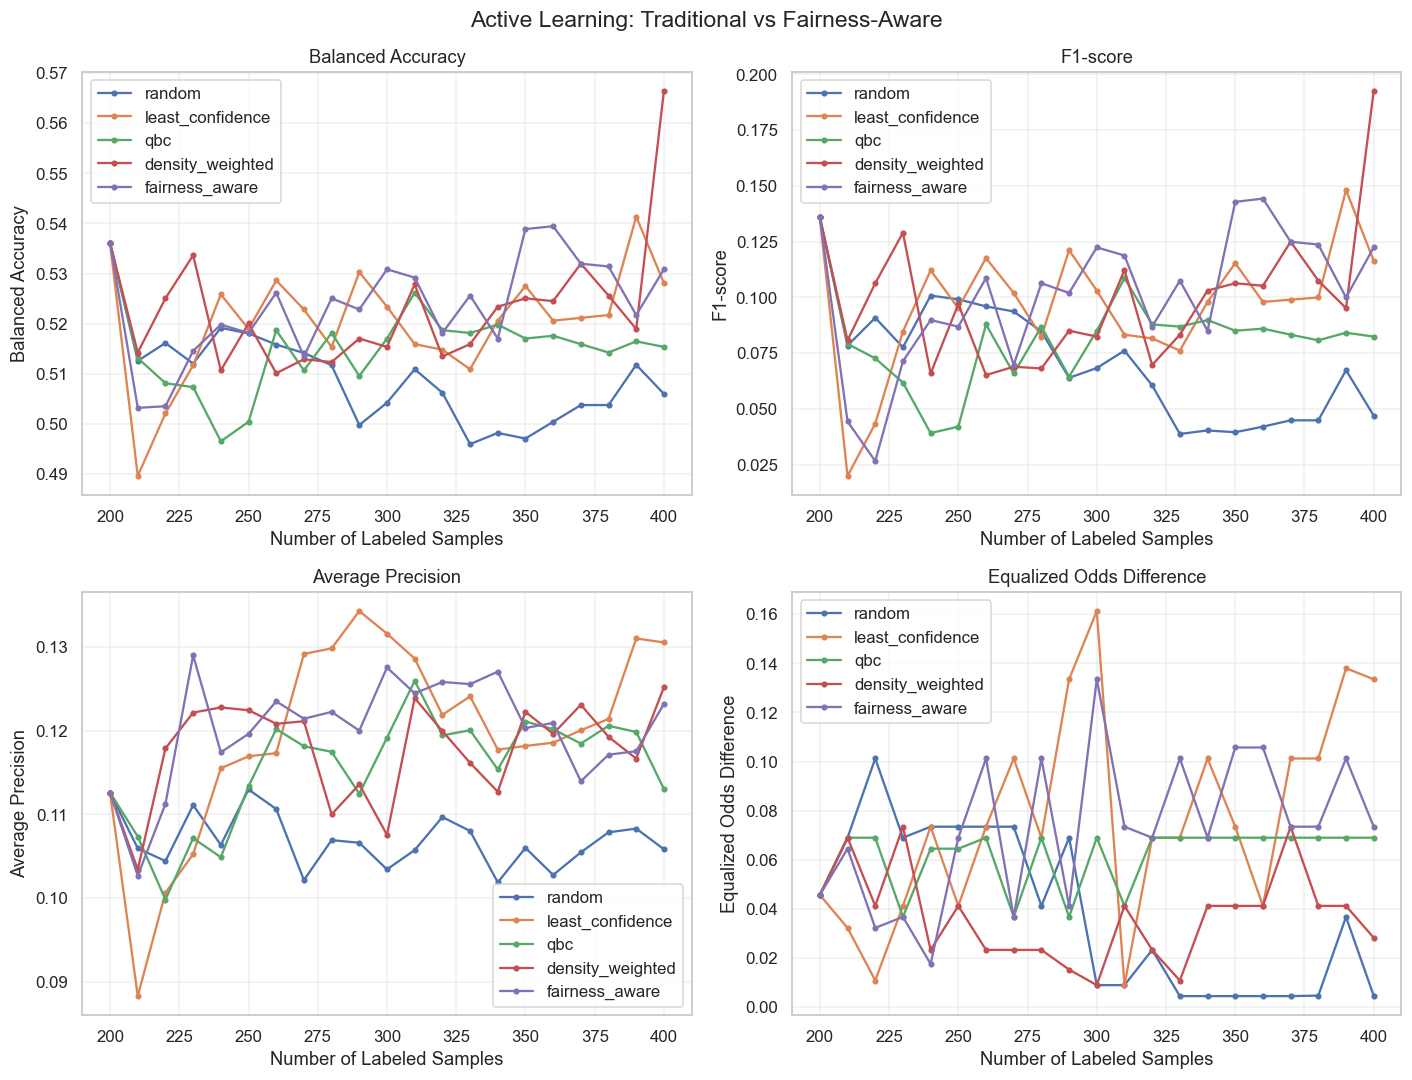

In [102]:

metrics = [
    ("balanced_accuracy", "Balanced Accuracy"),
    ("f1", "F1-score"),
    ("average_precision", "Average Precision"),
    ("equalized_odds", "Equalized Odds Difference")
]

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for ax, (metric, title) in zip(axes.flat, metrics):

    for strategy in strategies_comparison:

        subset = comparison_df[
            comparison_df["strategy"] == strategy
        ]

        ax.plot(
            subset["n_labeled"],
            subset[metric],
            marker="o",
            markersize=3,
            label=strategy
        )

    ax.set_title(title)
    ax.set_xlabel("Number of Labeled Samples")
    ax.set_ylabel(title)
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "Active Learning: Traditional vs Fairness-Aware",
    fontsize=15
)

plt.tight_layout()
plt.show()


### Human-in-the-Loop (HITL) e avaliação experimental

In [103]:

import numpy as np
import pandas as pd
from IPython.display import display

class HumanSupervisor:

    def __init__(self):
        self.decisions = []

    def review_batch(
        self,
        iteration,
        group_errors,
        proposed_races,
        cumulative_races,
        batch_size
    ):
        print("\n" + "=" * 60)
        print(f"HUMAN SUPERVISION - ITERATION {iteration}")
        print("=" * 60)

        print("\nGROUP ERROR PRIORITIES")
        print(f"Black: {group_errors[0]:.4f}")
        print(f"White: {group_errors[1]:.4f}")

        print("\nAUTOMATIC FAIRNESS-AWARE PROPOSAL")
        print(
            pd.Series(proposed_races)
            .value_counts()
            .reindex(["Black", "White"], fill_value=0)
        )

        print("\nPREVIOUSLY ACQUIRED EXAMPLES")
        print(
            pd.Series(cumulative_races)
            .value_counts()
            .reindex(["Black", "White"], fill_value=0)
        )

        print("\nACQUISITION POLICIES")
        print("[a] Automatic Fairness-Aware selection")
        print("[b] Balanced group acquisition")
        print("[c] Uncertainty-only acquisition")

        print("\nChoose a policy for the next batch.")
        print("This decision affects which examples")
        print("will be added to the training set.")

        while True:
            decision = input(
                "\nPolicy (a/b/c): "
            ).strip().lower()

            if decision in ["a", "b", "c"]:
                break

            print("Please choose a, b or c.")

        policy_names = {
            "a": "automatic_fairness_aware",
            "b": "balanced_acquisition",
            "c": "uncertainty_only"
        }

        print("\nREASON FOR INTERVENTION")
        print("[1] Maintain the automatic strategy")
        print("[2] Promote group representation")
        print("[3] Prioritize predictive uncertainty")
        print("[4] Other justified reason")

        while True:
            reason_code = input(
                "Reason (1-4): "
            ).strip()

            if reason_code in ["1", "2", "3", "4"]:
                break

            print("Invalid reason.")

        if reason_code == "4":
            reason = input(
                "Describe your reason: "
            ).strip()
        else:
            reason = {
                "1": "Maintain automatic strategy",
                "2": "Promote group representation",
                "3": "Prioritize uncertainty"
            }[reason_code]

        self.decisions.append({
            "iteration": iteration,
            "policy": policy_names[decision],
            "reason": reason,
            "black_priority": group_errors[0],
            "white_priority": group_errors[1],
            "batch_size": batch_size
        })

        print("\nSelected policy:", policy_names[decision])

        return decision


In [104]:

def supervised_query(
    model,
    X_pool,
    sensitive_pool,
    X_val,
    y_val,
    sensitive_val,
    policy,
    batch_size,
    alpha=0.5
):
    k = min(batch_size, len(X_pool))

    probabilities = model.predict_proba(X_pool)

    # Incerteza normalizada em classificação binária
    uncertainty = 2 * (
        1 - probabilities.max(axis=1)
    )

    # Ranking da estratégia Fairness-Aware
    ranked_fair = fairness_aware_query(
        model,
        X_pool,
        sensitive_pool,
        X_val,
        y_val,
        sensitive_val,
        batch_size=len(X_pool),
        alpha=alpha
    )

    if policy == "a":
        return ranked_fair[:k]

    if policy == "c":
        return np.argsort(uncertainty)[::-1][:k]

    if policy == "b":

        # Promover presença de ambos os grupos
        # dentro do orçamento do lote
        target_black = k // 2
        target_white = k - target_black

        black_ranked = [
            i for i in ranked_fair
            if sensitive_pool[i] == 0
        ]

        white_ranked = [
            i for i in ranked_fair
            if sensitive_pool[i] == 1
        ]

        selected = (
            black_ranked[:target_black]
            + white_ranked[:target_white]
        )

        # Preencher eventuais vagas mantendo o ranking
        selected_set = set(selected)

        for idx in ranked_fair:
            if len(selected) >= k:
                break

            if idx not in selected_set:
                selected.append(idx)
                selected_set.add(idx)

        return np.asarray(selected, dtype=int)

    raise ValueError("Unknown policy")


In [105]:

# X_pool_raw foi criado durante o pré-processamento.
# pool_idx foi criado na divisão de validação
# da fase Fairness-Aware.

X_pool_fair_raw = (
    X_pool_raw.iloc[pool_idx]
    .reset_index(drop=True)
)

assert len(X_pool_fair_raw) == len(X_pool_fair)

print("Original candidates:", len(X_pool_fair_raw))
print("Transformed candidates:", len(X_pool_fair))


Original candidates: 3204
Transformed candidates: 3204


In [106]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score

def run_human_in_the_loop(
    n_iterations=3,
    batch_size=3,
    alpha=0.5,
    seed=42
):
    supervisor = HumanSupervisor()

    X_labeled = X_initial.copy()
    y_labeled = y_initial.copy()

    X_unlabeled = X_pool_fair.copy()
    y_oracle = y_pool_fair.copy()
    sensitive_pool = sens_race_pool_fair.copy()

    # IDs estáveis para acompanhar aquisições
    candidate_ids = np.arange(len(X_unlabeled))

    acquired_races = []
    acquisition_log = []
    history = []

    for iteration in range(n_iterations + 1):

        print(f"\n========== ITERATION {iteration} ==========")

        model = RandomForestClassifier(
            n_estimators=200,
            max_depth=6,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=seed,
            n_jobs=-1
        )

        model.fit(X_labeled, y_labeled)

        # Avaliação no teste, apenas para análise posterior
        y_pred = model.predict(X_test)

        bal_acc = balanced_accuracy_score(
            y_test, y_pred
        )

        eod = calculate_fairness(
            y_test, y_pred, sens_race_test
        )

        history.append({
            "iteration": iteration,
            "n_labeled": len(y_labeled),
            "balanced_accuracy": bal_acc,
            "equalized_odds": eod
        })

        if iteration == n_iterations:
            break

        if len(X_unlabeled) == 0:
            break

        # Erros por grupo (validação, não teste)
        group_errors = group_error_scores(
            model, X_val, y_val, sens_race_val
        )

        # Proposta automática
        automatic_indices = fairness_aware_query(
            model,
            X_unlabeled,
            sensitive_pool,
            X_val,
            y_val,
            sens_race_val,
            batch_size=min(batch_size, len(X_unlabeled)),
            alpha=alpha
        )

        automatic_races = [
            "Black" if sensitive_pool[i] == 0
            else "White"
            for i in automatic_indices
        ]

        # DECISÃO HUMANA
        policy = supervisor.review_batch(
            iteration=iteration,
            group_errors=group_errors,
            proposed_races=automatic_races,
            cumulative_races=acquired_races,
            batch_size=batch_size
        )

        # Seleção de acordo com a decisão humana
        selected_indices = supervised_query(
            model,
            X_unlabeled,
            sensitive_pool,
            X_val,
            y_val,
            sens_race_val,
            policy=policy,
            batch_size=batch_size,
            alpha=alpha
        )

        # Registar seleção e diferenças face ao automático
        automatic_ids = set(
            candidate_ids[automatic_indices].tolist()
        )

        selected_ids = set(
            candidate_ids[selected_indices].tolist()
        )

        print("\nACQUISITION SUMMARY")
        print("Automatic candidate IDs:", sorted(automatic_ids))
        print("Selected candidate IDs:", sorted(selected_ids))

        changed = automatic_ids != selected_ids

        print("Human changed acquisition:", changed)

        probabilities = model.predict_proba(
            X_unlabeled[selected_indices]
        )[:, 1]

        for local_pos, idx in enumerate(selected_indices):

            group_id = int(sensitive_pool[idx])
            race = "Black" if group_id == 0 else "White"

            acquired_races.append(race)

            acquisition_log.append({
                "iteration": iteration,
                "candidate_id": int(candidate_ids[idx]),
                "race": race,
                "policy": {
                    "a": "automatic",
                    "b": "balanced",
                    "c": "uncertainty"
                }[policy],
                "callback_probability": float(
                    probabilities[local_pos]
                ),
                "historical_callback": int(y_oracle[idx]),
                "in_automatic_proposal": (
                    int(candidate_ids[idx]) in automatic_ids
                ),
                "acquisition_changed": changed
            })

        # Consultar oracle simulado
        X_new = X_unlabeled[selected_indices]
        y_new = y_oracle[selected_indices]

        X_labeled = np.vstack([
            X_labeled, X_new
        ])

        y_labeled = np.concatenate([
            y_labeled, y_new
        ])

        # Atualizar pool
        keep_mask = np.ones(
            len(X_unlabeled), dtype=bool
        )

        keep_mask[selected_indices] = False

        X_unlabeled = X_unlabeled[keep_mask]
        y_oracle = y_oracle[keep_mask]
        sensitive_pool = sensitive_pool[keep_mask]
        candidate_ids = candidate_ids[keep_mask]

    return (
        pd.DataFrame(history),
        pd.DataFrame(supervisor.decisions),
        pd.DataFrame(acquisition_log)
    )


In [110]:

hitl_history, human_decisions, acquisition_log = (
    run_human_in_the_loop(
        n_iterations=10,
        batch_size=3,
        alpha=0.5,
        seed=42
    )
)

print("\n--- HITL PERFORMANCE ---")
display(hitl_history)

print("\n--- HUMAN SUPERVISION DECISIONS ---")
display(human_decisions)

print("\n--- ACQUIRED EXAMPLES ---")
display(acquisition_log)

print("\n--- ACQUISITIONS BY RACE ---")
display(
    acquisition_log["race"]
    .value_counts()
    .reindex(["Black", "White"], fill_value=0)
)

human_decisions.to_csv(
    "human_supervision_log.csv",
    index=False
)

acquisition_log.to_csv(
    "hitl_acquisition_log.csv",
    index=False
)



========== ITERATION 0 ==========

HUMAN SUPERVISION - ITERATION 0

GROUP ERROR PRIORITIES
Black: 1.0000
White: 0.9457

AUTOMATIC FAIRNESS-AWARE PROPOSAL
Black    3
White    0
Name: count, dtype: int64

PREVIOUSLY ACQUIRED EXAMPLES
Black    0
White    0
Name: count, dtype: int64

ACQUISITION POLICIES
[a] Automatic Fairness-Aware selection
[b] Balanced group acquisition
[c] Uncertainty-only acquisition

Choose a policy for the next batch.
This decision affects which examples
will be added to the training set.

REASON FOR INTERVENTION
[1] Maintain the automatic strategy
[2] Promote group representation
[3] Prioritize predictive uncertainty
[4] Other justified reason

Selected policy: balanced_acquisition

ACQUISITION SUMMARY
Automatic candidate IDs: [279, 1076, 2783]
Selected candidate IDs: [367, 1024, 1076]
Human changed acquisition: True

========== ITERATION 1 ==========

HUMAN SUPERVISION - ITERATION 1

GROUP ERROR PRIORITIES
Black: 1.0000
White: 0.9565

AUTOMATIC FAIRNESS-AWARE PRO

,iteration,n_labeled,balanced_accuracy,equalized_odds
0,0,200,0.536110,0.045699
1,1,203,0.515390,0.068996
2,2,206,0.524754,0.073477
3,3,209,0.511729,0.101254
4,4,212,0.499817,0.068996
5,5,215,0.510617,0.101254
6,6,218,0.511729,0.041219
7,7,221,0.508160,0.068996
8,8,224,0.515066,0.101254
9,9,227,0.501253,0.036738



--- HUMAN SUPERVISION DECISIONS ---


,iteration,policy,reason,black_priority,white_priority,batch_size
0,0,balanced_acquisition,Promote group representation,1.0,0.945658,3
1,1,automatic_fairness_aware,Maintain automatic strategy,1.0,0.956537,3
2,2,balanced_acquisition,Promote group representation,1.0,0.957128,3
3,3,balanced_acquisition,Promote group representation,1.0,0.947224,3
4,4,automatic_fairness_aware,Maintain automatic strategy,1.0,0.948339,3
5,5,balanced_acquisition,Promote group representation,1.0,0.958326,3
6,6,balanced_acquisition,Promote group representation,1.0,0.956493,3
7,7,balanced_acquisition,Promote group representation,1.0,0.946843,3
8,8,automatic_fairness_aware,Maintain automatic strategy,1.0,0.962861,3
9,9,balanced_acquisition,Promote group representation,1.0,0.964963,3



--- ACQUIRED EXAMPLES ---


,iteration,candidate_id,race,policy,callback_probability,historical_callback,in_automatic_proposal,acquisition_changed
0,0,1076,Black,balanced,0.500754,0,True,True
1,0,367,White,balanced,0.499396,0,False,True
2,0,1024,White,balanced,0.500648,1,False,True
3,1,845,Black,automatic,0.500151,1,True,False
4,1,1248,Black,automatic,0.498807,0,True,False
5,1,1269,Black,automatic,0.497918,0,True,False
6,2,920,Black,balanced,0.499906,1,True,True
7,2,734,White,balanced,0.499355,0,False,True
8,2,2068,White,balanced,0.499083,0,False,True
9,3,237,Black,balanced,0.500091,0,True,True



--- ACQUISITIONS BY RACE ---


race
Black    16
White    14
Name: count, dtype: int64

### Final Evaluation - Automatic vs Human-in-the-Loop


=== FINAL PERFORMANCE COMPARISON ===


,Metric,Automatic Fairness-Aware,Fairness-Aware + HITL
0,Labeled Samples,230.0000,230.0000
1,Balanced Accuracy,0.5236,0.4852
2,Equalized Odds Difference,0.0735,0.0323



=== HUMAN SUPERVISION SUMMARY ===


,Metric,Value
0,Supervised Batches,10.0
1,Acquired Samples,30.0
2,Batches Changed by Human,7.0
3,Intervention Rate (%),70.0



=== HUMAN POLICY DECISIONS ===


,iteration,policy,reason,black_priority,white_priority
0,0,balanced_acquisition,Promote group representation,1.0,0.9457
1,1,automatic_fairness_aware,Maintain automatic strategy,1.0,0.9565
2,2,balanced_acquisition,Promote group representation,1.0,0.9571
3,3,balanced_acquisition,Promote group representation,1.0,0.9472
4,4,automatic_fairness_aware,Maintain automatic strategy,1.0,0.9483
5,5,balanced_acquisition,Promote group representation,1.0,0.9583
6,6,balanced_acquisition,Promote group representation,1.0,0.9565
7,7,balanced_acquisition,Promote group representation,1.0,0.9468
8,8,automatic_fairness_aware,Maintain automatic strategy,1.0,0.9629
9,9,balanced_acquisition,Promote group representation,1.0,0.9650



=== ACQUIRED SAMPLES BY RACE ===


,Acquired
race,
Black,16
White,14



=== ACQUISITIONS BY ITERATION ===


race,Black,White
iteration,,
0,1,2
1,3,0
2,1,2
3,1,2
4,3,0
5,1,2
6,1,2
7,1,2
8,3,0


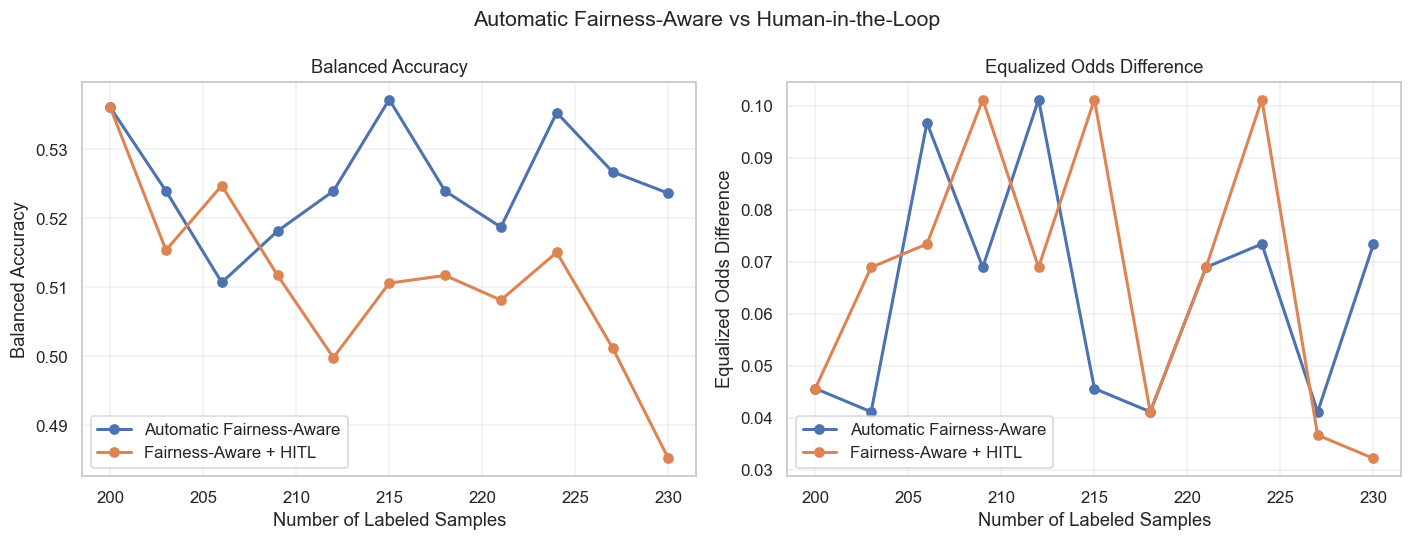

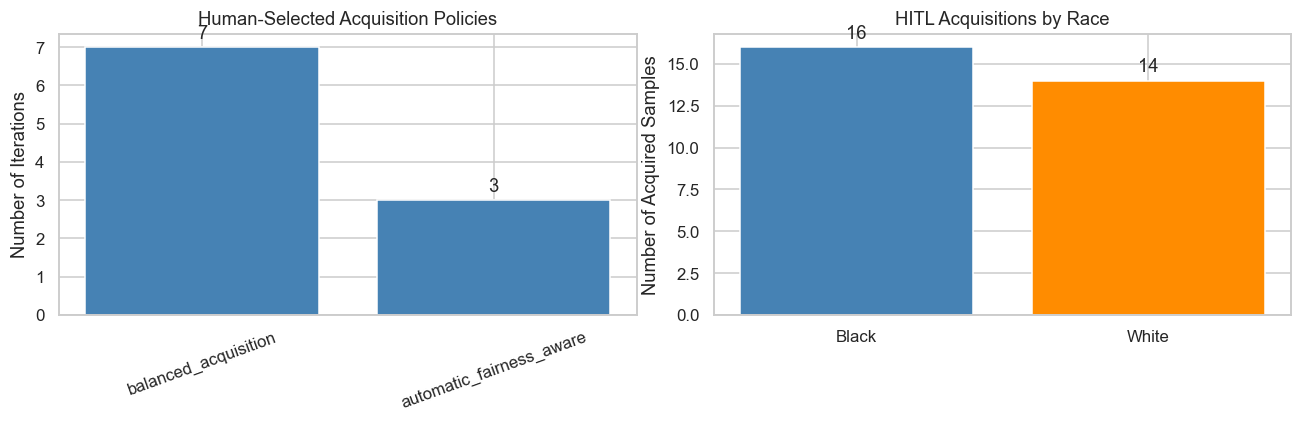


Final evaluation completed.


In [ ]:

# ============================================================
# FINAL EVALUATION: AUTOMATIC VS HUMAN-IN-THE-LOOP

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. EXECUTAR FAIRNESS-AWARE AUTOMÁTICO
#    Com o mesmo orçamento do HITL


auto_history = run_comparative_experiment(
    strategy="fairness_aware",
    n_iterations=10,
    batch_size=3,
    alpha=0.5,
    seed=42
)

# O HITL já foi executado anteriormente.
# Usamos hitl_history, human_decisions e acquisition_log.

# ------------------------------------------------------------
# 2. COMPARAÇÃO FINAL


auto_final = auto_history.iloc[-1]
hitl_final = hitl_history.iloc[-1]

comparison_final = pd.DataFrame({
    "Metric": [
        "Labeled Samples",
        "Balanced Accuracy",
        "Equalized Odds Difference"
    ],
    "Automatic Fairness-Aware": [
        auto_final["n_labeled"],
        auto_final["balanced_accuracy"],
        auto_final["equalized_odds"]
    ],
    "Fairness-Aware + HITL": [
        hitl_final["n_labeled"],
        hitl_final["balanced_accuracy"],
        hitl_final["equalized_odds"]
    ]
})

print("\n=== FINAL PERFORMANCE COMPARISON ===")
display(comparison_final.round(4))

# ------------------------------------------------------------
# 3. RESUMO DA SUPERVISÃO HUMANA


total_batches = len(human_decisions)
total_acquired = len(acquisition_log)

changed_batches = (
    acquisition_log.groupby("iteration")[
        "acquisition_changed"
    ].first().sum()
)

supervision_summary = pd.DataFrame({
    "Metric": [
        "Supervised Batches",
        "Acquired Samples",
        "Batches Changed by Human",
        "Intervention Rate (%)"
    ],
    "Value": [
        total_batches,
        total_acquired,
        int(changed_batches),
        round(
            100 * changed_batches / total_batches, 2
        ) if total_batches > 0 else 0
    ]
})

print("\n=== HUMAN SUPERVISION SUMMARY ===")
display(supervision_summary)

# ------------------------------------------------------------
# 4. POLÍTICAS ESCOLHIDAS PELO HUMANO


print("\n=== HUMAN POLICY DECISIONS ===")

display(
    human_decisions[
        ["iteration", "policy", "reason",
         "black_priority", "white_priority"]
    ].round(4)
)

# ------------------------------------------------------------
# 5. DISTRIBUIÇÃO RACIAL DAS AQUISIÇÕES


race_distribution = (
    acquisition_log["race"]
    .value_counts()
    .reindex(["Black", "White"], fill_value=0)
)

print("\n=== ACQUIRED SAMPLES BY RACE ===")
display(race_distribution.to_frame("Acquired"))

print("\n=== ACQUISITIONS BY ITERATION ===")

acquisitions_by_iteration = pd.crosstab(
    acquisition_log["iteration"],
    acquisition_log["race"]
).reindex(
    columns=["Black", "White"],
    fill_value=0
)

display(acquisitions_by_iteration)

# ------------------------------------------------------------
# 6. LEARNING CURVES: AUTOMATIC VS HITL


fig, axes = plt.subplots(1, 2, figsize=(13, 5))

experiments = [
    ("Automatic Fairness-Aware", auto_history),
    ("Fairness-Aware + HITL", hitl_history)
]

metrics = [
    ("balanced_accuracy", "Balanced Accuracy"),
    ("equalized_odds", "Equalized Odds Difference")
]

for ax, (metric, title) in zip(axes, metrics):

    for name, history in experiments:

        ax.plot(
            history["n_labeled"],
            history[metric],
            marker="o",
            linewidth=2,
            label=name
        )

    ax.set_title(title)
    ax.set_xlabel("Number of Labeled Samples")
    ax.set_ylabel(title)
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "Automatic Fairness-Aware vs Human-in-the-Loop",
    fontsize=14
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. GRÁFICOS DA SUPERVISÃO HUMANA


fig, axes = plt.subplots(1, 2, figsize=(12, 4))

policy_counts = human_decisions["policy"].value_counts()

axes[0].bar(
    policy_counts.index,
    policy_counts.values,
    color="steelblue"
)

axes[0].set_title("Human-Selected Acquisition Policies")
axes[0].set_ylabel("Number of Iterations")
axes[0].tick_params(axis="x", rotation=20)

axes[1].bar(
    race_distribution.index,
    race_distribution.values,
    color=["steelblue", "darkorange"]
)

axes[1].set_title("HITL Acquisitions by Race")
axes[1].set_ylabel("Number of Acquired Samples")

for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. GUARDAR RESULTADOS


comparison_final.to_csv(
    "final_comparison.csv",
    index=False
)

supervision_summary.to_csv(
    "supervision_summary.csv",
    index=False
)

human_decisions.to_csv(
    "human_supervision_log.csv",
    index=False
)

acquisition_log.to_csv(
    "hitl_acquisition_log.csv",
    index=False
)

print("\nFinal evaluation completed.")


### Final Experimentation with Multiple Seeds + F1-Score Graphic


Running seed 10...

Running seed 21...

Running seed 42...

Running seed 73...

Running seed 99...

All experiments completed.

=== FINAL RESULTS (MEAN +/- STD) ===


balanced_accuracy              f1         average_precision  \
                        mean     std    mean     std              mean   
mode                                                                     
automatic             0.5277  0.0102  0.1122  0.0277            0.1244   
supervised            0.5234  0.0101  0.1010  0.0315            0.1255   

                   equalized_odds         positive_predictions           
               std           mean     std                 mean      std  
mode                                                                     
automatic   0.0064         0.0670  0.0248                 33.8  16.1617  
supervised  0.0132         0.0389  0.0235                 30.0  11.8954

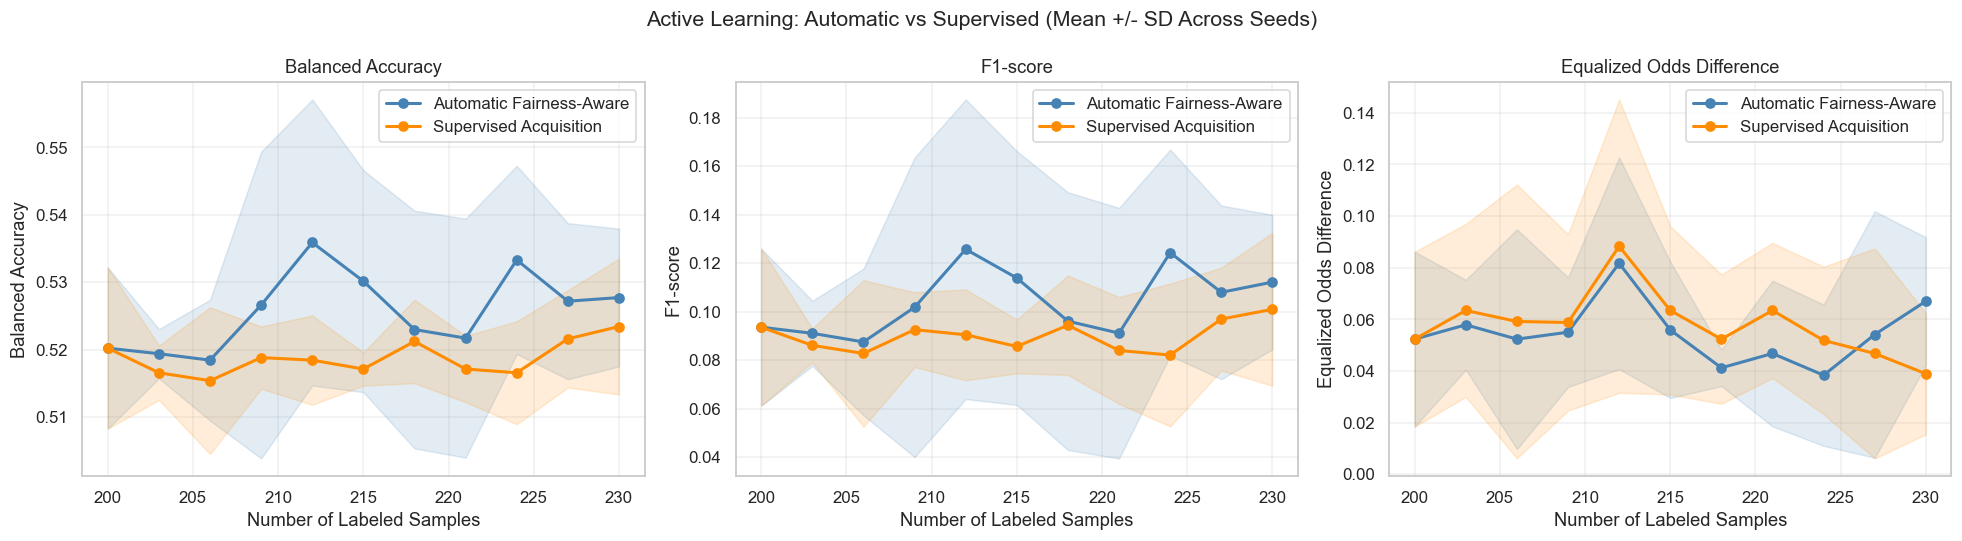


=== ACQUISITION SUMMARY BY SEED ===


,mode,seed,black_acquired,white_acquired,changed_batches
0,automatic,10,30,0,0
1,automatic,21,30,0,0
2,automatic,42,25,5,0
3,automatic,73,30,0,0
4,automatic,99,30,0,0
5,supervised,10,10,20,10
6,supervised,21,11,19,9
7,supervised,42,10,20,10
8,supervised,73,10,20,10
9,supervised,99,10,20,10



=== AVERAGE ACQUISITIONS BY MODE ===


,black_acquired,white_acquired,changed_batches
mode,,,
automatic,29.0,1.0,0.0
supervised,10.2,19.8,9.8



Final experimentation completed.


In [ ]:

# ============================================================
# FINAL EXPERIMENTATION: MULTIPLE SEEDS
# AUTOMATIC FAIRNESS-AWARE VS SUPERVISED ACQUISITION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

# ============================================================
# 1. EXPERIMENTAL CONFIGURATION

SEEDS = [10, 21, 42, 73, 99]
N_ITERATIONS = 10
BATCH_SIZE = 3
ALPHA = 0.5

# Limiar da política supervisionada
PRIORITY_THRESHOLD = 0.10

# ============================================================
# 2. REPRODUCIBLE SUPERVISION POLICY

def supervision_policy(
    proposed_groups,
    group_errors,
    threshold=0.10
):
    """
    Simula uma política de supervisão humana.

    Se a aquisição automática selecionar apenas um grupo
    e as prioridades forem semelhantes, aplica Balanced.

    Caso contrário, mantém Automatic Fairness-Aware.
    """

    unique_groups = np.unique(proposed_groups)

    priority_gap = abs(
        group_errors[0] - group_errors[1]
    )

    if len(unique_groups) == 1 and priority_gap < threshold:
        return "b"

    return "a"


# ============================================================
# 3. EXPERIMENTAL ACTIVE LEARNING LOOP

def run_final_experiment(
    mode,
    seed,
    n_iterations=N_ITERATIONS,
    batch_size=BATCH_SIZE,
    alpha=ALPHA
):

    # Mesmos exemplos iniciais e mesma pool
    X_labeled = X_initial.copy()
    y_labeled = y_initial.copy()

    X_unlabeled = X_pool_fair.copy()
    y_oracle = y_pool_fair.copy()
    sensitive_pool = sens_race_pool_fair.copy()

    history = []
    acquisition_history = []

    for iteration in range(n_iterations + 1):

        # ----------------------------------------
        # TRAIN MODEL

        model = RandomForestClassifier(
            n_estimators=200,
            max_depth=6,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=seed,
            n_jobs=-1
        )

        model.fit(X_labeled, y_labeled)

        # ----------------------------------------
        # EVALUATION

        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        balanced_acc = balanced_accuracy_score(
            y_test, y_pred
        )

        f1 = f1_score(
            y_test,
            y_pred,
            zero_division=0
        )

        ap = average_precision_score(
            y_test, y_prob
        )

        eod = calculate_fairness(
            y_test,
            y_pred,
            sens_race_test
        )

        history.append({
            "mode": mode,
            "seed": seed,
            "iteration": iteration,
            "n_labeled": len(y_labeled),
            "balanced_accuracy": balanced_acc,
            "f1": f1,
            "average_precision": ap,
            "equalized_odds": eod,
            "positive_predictions": int(y_pred.sum())
        })

        if iteration == n_iterations:
            break

        if len(X_unlabeled) == 0:
            break

        # ----------------------------------------
        # AUTOMATIC ACQUISITION PROPOSAL

        automatic_idx = fairness_aware_query(
            model,
            X_unlabeled,
            sensitive_pool,
            X_val,
            y_val,
            sens_race_val,
            batch_size=min(batch_size, len(X_unlabeled)),
            alpha=alpha
        )

        # ----------------------------------------
        # SUPERVISION

        policy = "a"

        if mode == "supervised":

            group_errors = group_error_scores(
                model,
                X_val,
                y_val,
                sens_race_val
            )

            proposed_groups = sensitive_pool[
                automatic_idx
            ]

            policy = supervision_policy(
                proposed_groups,
                group_errors,
                threshold=PRIORITY_THRESHOLD
            )

        elif mode != "automatic":
            raise ValueError("Invalid mode")

        # ----------------------------------------
        # FINAL SAMPLE SELECTION

        if policy == "a":

            selected_idx = automatic_idx

        else:

            selected_idx = supervised_query(
                model,
                X_unlabeled,
                sensitive_pool,
                X_val,
                y_val,
                sens_race_val,
                policy=policy,
                batch_size=batch_size,
                alpha=alpha
            )

        # Registar aquisições
        selected_groups = sensitive_pool[selected_idx]

        acquisition_history.append({
            "mode": mode,
            "seed": seed,
            "iteration": iteration,
            "policy": policy,
            "black_acquired": int(
                np.sum(selected_groups == 0)
            ),
            "white_acquired": int(
                np.sum(selected_groups == 1)
            ),
            "selection_changed": not np.array_equal(
                np.sort(selected_idx),
                np.sort(automatic_idx)
            )
        })

        # ----------------------------------------
        # ORACLE: REVEAL HISTORICAL LABELS

        X_new = X_unlabeled[selected_idx]
        y_new = y_oracle[selected_idx]

        # ----------------------------------------
        # UPDATE LABELED DATASET


        X_labeled = np.vstack([
            X_labeled, X_new
        ])

        y_labeled = np.concatenate([
            y_labeled, y_new
        ])

        # ----------------------------------------
        # REMOVE ACQUIRED SAMPLES

        keep_mask = np.ones(
            len(X_unlabeled),
            dtype=bool
        )

        keep_mask[selected_idx] = False

        X_unlabeled = X_unlabeled[keep_mask]
        y_oracle = y_oracle[keep_mask]
        sensitive_pool = sensitive_pool[keep_mask]

    return (
        pd.DataFrame(history),
        pd.DataFrame(acquisition_history)
    )


# ============================================================
# 4. EXECUTE MULTIPLE SEEDS

all_results = []
all_acquisitions = []

for seed in SEEDS:

    print(f"\nRunning seed {seed}...")

    for mode in ["automatic", "supervised"]:

        result, acquisition = run_final_experiment(
            mode=mode,
            seed=seed
        )

        all_results.append(result)
        all_acquisitions.append(acquisition)

final_results_df = pd.concat(
    all_results,
    ignore_index=True
)

final_acquisitions_df = pd.concat(
    all_acquisitions,
    ignore_index=True
)

print("\nAll experiments completed.")


# ============================================================
# 5. FINAL PERFORMANCE TABLE

final_rows = final_results_df[
    final_results_df["iteration"] == N_ITERATIONS
]

metrics_to_summarize = [
    "balanced_accuracy",
    "f1",
    "average_precision",
    "equalized_odds",
    "positive_predictions"
]

summary = (
    final_rows
    .groupby("mode")[metrics_to_summarize]
    .agg(["mean", "std"])
)

print("\n=== FINAL RESULTS (MEAN +/- STD) ===")

display(summary.round(4))


# ============================================================
# 6. LEARNING CURVES: MEAN +/- STANDARD DEVIATION

metrics_to_plot = [
    ("balanced_accuracy", "Balanced Accuracy"),
    ("f1", "F1-score"),
    ("equalized_odds", "Equalized Odds Difference")
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

colors = {
    "automatic": "steelblue",
    "supervised": "darkorange"
}

labels = {
    "automatic": "Automatic Fairness-Aware",
    "supervised": "Supervised Acquisition"
}

for ax, (metric, title) in zip(axes, metrics_to_plot):

    for mode in ["automatic", "supervised"]:

        subset = final_results_df[
            final_results_df["mode"] == mode
        ]

        stats = (
            subset
            .groupby("n_labeled")[metric]
            .agg(["mean", "std"])
            .reset_index()
        )

        x = stats["n_labeled"].to_numpy()
        mean = stats["mean"].to_numpy()
        std = stats["std"].fillna(0).to_numpy()

        ax.plot(
            x,
            mean,
            marker="o",
            linewidth=2,
            color=colors[mode],
            label=labels[mode]
        )

        ax.fill_between(
            x,
            mean - std,
            mean + std,
            color=colors[mode],
            alpha=0.15
        )

    ax.set_title(title)
    ax.set_xlabel("Number of Labeled Samples")
    ax.set_ylabel(title)
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "Active Learning: Automatic vs Supervised "
    "(Mean +/- SD Across Seeds)",
    fontsize=14
)

plt.tight_layout()
plt.show()


# ============================================================
# 7. ACQUISITION ANALYSIS

acquisition_summary = (
    final_acquisitions_df
    .groupby(["mode", "seed"])
    .agg(
        black_acquired=("black_acquired", "sum"),
        white_acquired=("white_acquired", "sum"),
        changed_batches=("selection_changed", "sum")
    )
    .reset_index()
)

print("\n=== ACQUISITION SUMMARY BY SEED ===")
display(acquisition_summary)

print("\n=== AVERAGE ACQUISITIONS BY MODE ===")

display(
    acquisition_summary
    .groupby("mode")[
        ["black_acquired",
         "white_acquired",
         "changed_batches"]
    ]
    .mean()
    .round(2)
)

# ============================================================
# 8. SAVE RESULTS

final_results_df.to_csv(
    "multiple_seeds_results.csv",
    index=False
)

final_acquisitions_df.to_csv(
    "multiple_seeds_acquisitions.csv",
    index=False
)

summary.to_csv(
    "multiple_seeds_summary.csv"
)

print("\nFinal experimentation completed.")
